# Eksperimen Perhitungan SAW-TOPSIS

In [1]:
import pandas as pd
import numpy as np
from IPython.display import display

NAMA_FILE = 'DATASET Sistem Pengambilan Keputusan.csv'
BOBOT = {'C1':0.15,'C2':0.20,'C3':0.15,'C4':0.10,'C5':0.10,'C6':0.15,'C7':0.05,'C8':0.10}
ATRIBUT = {'C1':'Benefit','C2':'Cost','C3':'Cost','C4':'Cost','C5':'Cost','C6':'Cost','C7':'Cost','C8':'Cost'}
KODE = list(BOBOT)


In [2]:
import pandas as pd
import os

# Identitas dataset
NAMA_DATASET = "Dataset_SPK_Fasilitas Kesehatan"
NAMA_FILE = NAMA_DATASET + ".csv"

# Memeriksa keberadaan file
if not os.path.isfile(NAMA_FILE):
    raise FileNotFoundError(
        f"File '{NAMA_FILE}' tidak ditemukan. "
        "Pastikan file berada di folder kerja notebook."
    )

# Membaca CSV tanpa menetapkan header
raw = pd.read_csv(NAMA_FILE, header=None, dtype=str)

# Mencari baris yang memuat kata "Kecamatan"
baris_header = None
kolom_kecamatan = None

for i in range(len(raw)):
    nilai_baris = raw.iloc[i].astype(str).str.strip().str.lower()

    posisi = [
        j for j, nilai in enumerate(nilai_baris)
        if nilai == "kecamatan"
    ]

    if posisi:
        baris_header = i
        kolom_kecamatan = posisi[0]
        break

if baris_header is None:
    raise ValueError(
        "Kolom 'Kecamatan' tidak ditemukan. "
        "Periksa isi dan format file CSV."
    )

# Mengambil baris header
header = raw.iloc[baris_header].fillna("").astype(str).str.strip()

# Mengambil data setelah baris header
df = raw.iloc[baris_header + 1:].copy()
df.columns = header

# Mengambil kolom Kecamatan dan 8 kriteria
data = df.iloc[
    :,
    [kolom_kecamatan] +
    list(range(kolom_kecamatan + 1, kolom_kecamatan + 9))
].copy()

data.columns = ["Kecamatan"] + KODE

# Membersihkan nama kecamatan
data["Kecamatan"] = data["Kecamatan"].astype(str).str.strip()

# Menghapus baris kosong
data = data[
    data["Kecamatan"].notna()
    & (data["Kecamatan"] != "")
    & (data["Kecamatan"].str.lower() != "nan")
].copy()

# Mengubah nilai kriteria menjadi numerik
for c in KODE:
    data[c] = (
        data[c]
        .astype(str)
        .str.strip()
        .replace({"-": "0", "": "0", "nan": "0"})
    )

    data[c] = pd.to_numeric(data[c], errors="raise")

# Mengatur ulang indeks
data = data.reset_index(drop=True)

# Menampilkan identitas dan dataset
print("Nama Dataset :", NAMA_DATASET)
print("Nama File    :", NAMA_FILE)
print("Jumlah Kecamatan :", len(data))
print("Jumlah Kriteria  :", len(KODE))

display(data)

Nama Dataset : Dataset_SPK_Fasilitas Kesehatan
Nama File    : Dataset_SPK_Fasilitas Kesehatan.csv
Jumlah Kecamatan : 15
Jumlah Kriteria  : 8


,Kecamatan,C1,C2,C3,C4,C5,C6,C7,C8
0,Mariso,32306,24,1,1,4,3,1,7
1,Mamajang,25811,26,2,1,4,2,1,12
2,Tamalate,9363,50,3,1,8,4,1,10
3,Rappocini,16346,64,4,3,7,4,1,11
4,Makassar,32530,33,0,1,2,3,1,11
5,Ujung Pandang,9459,10,3,5,6,1,1,8
6,Wajo,14769,17,2,2,2,2,0,7
7,Bontoala,26307,17,2,1,5,2,3,7
8,Ujung Tanah,8346,29,1,0,1,2,2,5
9,Kepulauan Sangkarrang,9745,36,0,0,0,2,1,0


Tabel bobot

In [3]:
tabel_bobot = pd.DataFrame({'Kode':KODE,'Atribut':[ATRIBUT[k] for k in KODE],'Bobot':[BOBOT[k] for k in KODE]})
display(tabel_bobot)
print('Total bobot =', sum(BOBOT.values()))


,Kode,Atribut,Bobot
0,C1,Benefit,0.15
1,C2,Cost,0.20
2,C3,Cost,0.15
3,C4,Cost,0.10
4,C5,Cost,0.10
5,C6,Cost,0.15
6,C7,Cost,0.05
7,C8,Cost,0.10


Total bobot = 1.0


Normalisasi SAW (R)

Benefit = x/max(x); Cost = min(x)/x; jika minimum 0, Excel memakai (min+1)/(x+1).

In [4]:
X = data[KODE].to_numpy(dtype=float)
R = np.zeros_like(X)
for j,k in enumerate(KODE):
    col = X[:,j]
    if ATRIBUT[k] == 'Benefit':
        R[:,j] = col/col.max() if col.max()!=0 else 0
    else:
        mn = col.min()
        R[:,j] = (mn+1)/(col+1) if mn==0 else np.divide(mn,col,out=np.zeros_like(col),where=col!=0)
tabel_R = pd.DataFrame(R,columns=KODE)
tabel_R.insert(0,'Kecamatan',data['Kecamatan'])
display(tabel_R.round(6))


,Kecamatan,C1,C2,C3,C4,C5,C6,C7,C8
0,Mariso,0.993114,0.416667,0.500000,0.500000,0.200000,0.333333,0.500000,0.125000
1,Mamajang,0.793452,0.384615,0.333333,0.500000,0.200000,0.500000,0.500000,0.076923
2,Tamalate,0.287827,0.200000,0.250000,0.500000,0.111111,0.250000,0.500000,0.090909
3,Rappocini,0.502490,0.156250,0.200000,0.250000,0.125000,0.250000,0.500000,0.083333
4,Makassar,1.000000,0.303030,1.000000,0.500000,0.333333,0.333333,0.500000,0.083333
5,Ujung Pandang,0.290778,1.000000,0.250000,0.166667,0.142857,1.000000,0.500000,0.111111
6,Wajo,0.454012,0.588235,0.333333,0.333333,0.333333,0.500000,1.000000,0.125000
7,Bontoala,0.808700,0.588235,0.333333,0.500000,0.166667,0.500000,0.250000,0.125000
8,Ujung Tanah,0.256563,0.344828,0.500000,1.000000,0.500000,0.500000,0.333333,0.166667
9,Kepulauan Sangkarrang,0.299570,0.277778,1.000000,1.000000,1.000000,0.500000,0.500000,1.000000


Normalisasi Pembobotan SAW (Y = w × R)

In [5]:
w = np.array([BOBOT[k] for k in KODE])
Y = R*w
tabel_Y = pd.DataFrame(Y,columns=KODE)
tabel_Y.insert(0,'Kecamatan',data['Kecamatan'])
display(tabel_Y.round(6))


,Kecamatan,C1,C2,C3,C4,C5,C6,C7,C8
0,Mariso,0.148967,0.083333,0.0750,0.050000,0.020000,0.0500,0.025000,0.012500
1,Mamajang,0.119018,0.076923,0.0500,0.050000,0.020000,0.0750,0.025000,0.007692
2,Tamalate,0.043174,0.040000,0.0375,0.050000,0.011111,0.0375,0.025000,0.009091
3,Rappocini,0.075374,0.031250,0.0300,0.025000,0.012500,0.0375,0.025000,0.008333
4,Makassar,0.150000,0.060606,0.1500,0.050000,0.033333,0.0500,0.025000,0.008333
5,Ujung Pandang,0.043617,0.200000,0.0375,0.016667,0.014286,0.1500,0.025000,0.011111
6,Wajo,0.068102,0.117647,0.0500,0.033333,0.033333,0.0750,0.050000,0.012500
7,Bontoala,0.121305,0.117647,0.0500,0.050000,0.016667,0.0750,0.012500,0.012500
8,Ujung Tanah,0.038484,0.068966,0.0750,0.100000,0.050000,0.0750,0.016667,0.016667
9,Kepulauan Sangkarrang,0.044935,0.055556,0.1500,0.100000,0.100000,0.0750,0.025000,0.100000


TOPSIS: solusi ideal, jarak, preferensi, ranking

In [6]:
# Menentukan solusi ideal positif dan negatif
A_plus = Y.max(axis=0)
A_minus = Y.min(axis=0)

# Membuat tabel solusi ideal
tabel_solusi_ideal = pd.DataFrame({
    'Kriteria': KODE,
    'Solusi Ideal Positif (A+)': A_plus,
    'Solusi Ideal Negatif (A-)': A_minus
})

display(tabel_solusi_ideal.round(4))

,Kriteria,Solusi Ideal Positif (A+),Solusi Ideal Negatif (A-)
0,C1,0.15,0.0155
1,C2,0.20,0.0312
2,C3,0.15,0.0250
3,C4,0.10,0.0167
4,C5,0.10,0.0111
5,C6,0.15,0.0300
6,C7,0.05,0.0100
7,C8,0.10,0.0077


In [7]:
# Menghitung jarak ke solusi ideal positif dan negatif
D_plus = np.sqrt(((Y - A_plus) ** 2).sum(axis=1))
D_minus = np.sqrt(((Y - A_minus) ** 2).sum(axis=1))

# Menghitung nilai preferensi TOPSIS
V = np.divide(
    D_minus,
    D_plus + D_minus,
    out=np.zeros_like(D_minus, dtype=float),
    where=(D_plus + D_minus) != 0
)

# Membuat tabel hasil TOPSIS
hasil_topsis = pd.DataFrame({
    'No': range(1, len(data) + 1),
    'Kecamatan': data['Kecamatan'].values,
    'D+ (Jarak ke A+)': D_plus,
    'D- (Jarak ke A-)': D_minus,
    'Nilai Preferensi (V)': V
})

# Menentukan ranking berdasarkan nilai preferensi terbesar
hasil_topsis['Ranking'] = (
    hasil_topsis['Nilai Preferensi (V)']
    .rank(method='min', ascending=False)
    .astype(int)
)

# Mengurutkan hasil berdasarkan ranking
hasil_topsis = (
    hasil_topsis
    .sort_values(['Ranking', 'Kecamatan'])
    .reset_index(drop=True)
)

# Menampilkan tabel hasil TOPSIS
display(hasil_topsis.round(4))

,No,Kecamatan,D+ (Jarak ke A+),D- (Jarak ke A-),Nilai Preferensi (V),Ranking
0,10,Kepulauan Sangkarrang,0.1953,0.2066,0.5141,1
1,6,Ujung Pandang,0.2163,0.2099,0.4925,2
2,5,Makassar,0.2131,0.1919,0.4738,3
3,8,Bontoala,0.2043,0.1500,0.4233,4
4,1,Mariso,0.2154,0.1577,0.4226,5
5,2,Mamajang,0.2231,0.1299,0.3680,6
6,7,Wajo,0.2137,0.1236,0.3665,7
7,11,Tallo,0.2486,0.1421,0.3636,8
8,9,Ujung Tanah,0.2267,0.1227,0.3512,9
9,14,Biringkanaya,0.2644,0.1256,0.3220,10


In [8]:
# Membuat tabel hasil akhir metode gabungan SAW-TOPSIS
hasil_akhir = pd.DataFrame({
    'Ranking': hasil_topsis['Ranking'],
    'Kecamatan': hasil_topsis['Kecamatan'],
    'Nilai Preferensi': hasil_topsis['Nilai Preferensi (V)']
})

# Mengurutkan berdasarkan ranking dari terkecil
hasil_akhir = (
    hasil_akhir
    .sort_values('Ranking')
    .reset_index(drop=True)
)

# Menampilkan hasil akhir
display(hasil_akhir.round(4))

,Ranking,Kecamatan,Nilai Preferensi
0,1,Kepulauan Sangkarrang,0.5141
1,2,Ujung Pandang,0.4925
2,3,Makassar,0.4738
3,4,Bontoala,0.4233
4,5,Mariso,0.4226
5,6,Mamajang,0.3680
6,7,Wajo,0.3665
7,8,Tallo,0.3636
8,9,Ujung Tanah,0.3512
9,10,Biringkanaya,0.3220


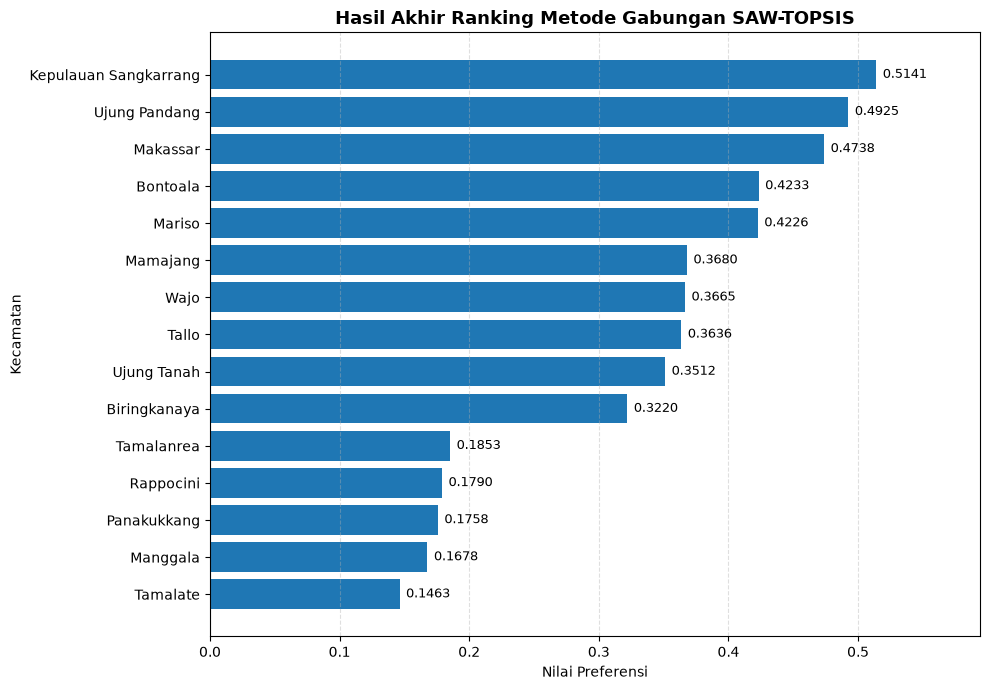

In [9]:
import matplotlib.pyplot as plt

# Mengurutkan data berdasarkan ranking
data_grafik = hasil_akhir.sort_values(
    'Ranking', ascending=False
)

# Membuat grafik
plt.figure(figsize=(10, 7))

bars = plt.barh(
    data_grafik['Kecamatan'],
    data_grafik['Nilai Preferensi']
)

# Menambahkan nilai pada setiap batang
for bar in bars:
    nilai = bar.get_width()
    plt.text(
        nilai + 0.005,
        bar.get_y() + bar.get_height() / 2,
        f'{nilai:.4f}',
        va='center',
        fontsize=9
    )

# Pengaturan tampilan grafik
plt.title(
    'Hasil Akhir Ranking Metode Gabungan SAW-TOPSIS',
    fontsize=13,
    fontweight='bold'
)
plt.xlabel('Nilai Preferensi')
plt.ylabel('Kecamatan')
plt.grid(axis='x', linestyle='--', alpha=0.4)
plt.xlim(0, data_grafik['Nilai Preferensi'].max() + 0.08)
plt.tight_layout()

plt.show()